In [1]:
import pandas as pd
print(pd.__version__)

2.3.3


In [2]:
import numpy as np
np.random.seed(42)

In [3]:
vendors = ["Alpha Supplies Ltd", "Bright Office Co", "City Cleaning Services",
           "Delta IT Solutions", "Evergreen Catering", "Fast Freight Ltd",
           "Green Energy UK", "Harbour Print Ltd", "Iron Security Ltd",
           "Jupiter Consulting"]
n = 200

invoices = pd.DataFrame({
    "invoice_id": ["INV-" + str(1000 + i) for i in range(n)],
    "vendor": np.random.choice(vendors, n),
    "invoice_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(np.random.randint(0, 365, n), unit="D"),
    "amount": np.round(np.random.uniform(100, 5000, n), 2)
})
invoices.head()

,invoice_id,vendor,invoice_date,amount
0,INV-1000,Green Energy UK,2025-08-28,3996.41
1,INV-1001,Delta IT Solutions,2025-05-24,1427.08
2,INV-1002,Harbour Print Ltd,2025-04-07,2250.96
3,INV-1003,Evergreen Catering,2025-07-20,484.44
4,INV-1004,Green Energy UK,2025-05-04,224.22


In [4]:
# 5 exact copies of real invoices
exact_dupes = invoices.sample(5, random_state=1)

# 4 invoices re-sent with a new number, 3 days later
close_dupes = invoices.sample(4, random_state=2).copy()
close_dupes["invoice_id"] = ["INV-" + str(2000 + i) for i in range(4)]
close_dupes["invoice_date"] = close_dupes["invoice_date"] + pd.Timedelta(days=3)

In [5]:
# 4 invoices where the number was typed without the hyphen (INV-1005 -> INV1005)
near_dupes = invoices.sample(4, random_state=3).copy()
near_dupes["invoice_id"] = near_dupes["invoice_id"].str.replace("-", "")

In [6]:
invoices = pd.concat([invoices, exact_dupes, close_dupes, near_dupes], ignore_index=True)
invoices = invoices.sample(frac=1, random_state=4).reset_index(drop=True)
invoices.to_csv("data/invoices.csv", index=False)
print("Rows saved:", len(invoices))

Rows saved: 213


In [7]:
df = pd.read_csv("data/invoices.csv", parse_dates=["invoice_date"])
df.head()

,invoice_id,vendor,invoice_date,amount
0,INV-1034,Green Energy UK,2025-09-11,948.69
1,INV-1198,Bright Office Co,2025-06-07,4563.54
2,INV-1111,City Cleaning Services,2025-04-05,3786.64
3,INV-1018,Fast Freight Ltd,2025-02-08,2816.33
4,INV-1092,Evergreen Catering,2025-10-31,605.31


In [8]:
print("Rows and columns:", df.shape)
print(df.dtypes)
print("Missing values:")
print(df.isnull().sum())
print("Total invoice value: £", round(df["amount"].sum(), 2))
print("Zero or negative amounts:", (df["amount"] <= 0).sum())

Rows and columns: (213, 4)
invoice_id              object
vendor                  object
invoice_date    datetime64[ns]
amount                 float64
dtype: object
Missing values:
invoice_id      0
vendor          0
invoice_date    0
amount          0
dtype: int64
Total invoice value: £ 550993.82
Zero or negative amounts: 0


In [9]:
test1 = df[df.duplicated(keep="first")]
print("Test 1 - exact duplicates found:", len(test1))
test1

Test 1 - exact duplicates found: 5


,invoice_id,vendor,invoice_date,amount
18,INV-1034,Green Energy UK,2025-09-11,948.69
106,INV-1102,Green Energy UK,2025-02-15,1664.64
136,INV-1040,Iron Security Ltd,2025-04-09,1935.60
162,INV-1184,City Cleaning Services,2025-01-05,1459.17
205,INV-1058,Fast Freight Ltd,2025-06-02,4809.83


In [10]:
pairs = df.merge(df, on=["vendor", "amount"], suffixes=("_1", "_2"))
pairs = pairs[pairs["invoice_id_1"] < pairs["invoice_id_2"]]
pairs["days_apart"] = (pairs["invoice_date_2"] - pairs["invoice_date_1"]).dt.days.abs()

test2 = pairs[pairs["days_apart"] <= 7]
print("Test 2 - same vendor + amount within 7 days:", len(test2))
test2

Test 2 - same vendor + amount within 7 days: 9


,invoice_id_1,vendor,invoice_date_1,amount,invoice_id_2,invoice_date_2,days_apart
20,INV-1040,Iron Security Ltd,2025-04-09,1935.60,INV1040,2025-04-09,0
36,INV-1199,Fast Freight Ltd,2025-05-27,4130.43,INV-2003,2025-05-30,3
45,INV-1139,Delta IT Solutions,2025-09-03,3791.55,INV1139,2025-09-03,0
50,INV-1112,Evergreen Catering,2025-04-09,3978.74,INV-2000,2025-04-12,3
76,INV-1029,Delta IT Solutions,2025-12-12,3547.92,INV-2001,2025-12-15,3
152,INV-1040,Iron Security Ltd,2025-04-09,1935.60,INV1040,2025-04-09,0
164,INV-1051,Alpha Supplies Ltd,2025-04-23,2919.82,INV1051,2025-04-23,0
172,INV-1182,Alpha Supplies Ltd,2025-03-01,2332.72,INV-2002,2025-03-04,3
236,INV-1197,Delta IT Solutions,2025-04-16,896.82,INV1197,2025-04-16,0


In [11]:
df["clean_id"] = df["invoice_id"].str.upper().str.replace("-", "").str.replace(" ", "")

pairs3 = df.merge(df, on=["vendor", "clean_id"], suffixes=("_1", "_2"))
test3 = pairs3[pairs3["invoice_id_1"] < pairs3["invoice_id_2"]]
print("Test 3 - near-duplicate invoice numbers:", len(test3))
test3

Test 3 - near-duplicate invoice numbers: 5


,invoice_id_1,vendor,invoice_date_1,amount_1,clean_id,invoice_id_2,invoice_date_2,amount_2
20,INV-1040,Iron Security Ltd,2025-04-09,1935.60,INV1040,INV1040,2025-04-09,1935.60
44,INV-1139,Delta IT Solutions,2025-09-03,3791.55,INV1139,INV1139,2025-09-03,3791.55
147,INV-1040,Iron Security Ltd,2025-04-09,1935.60,INV1040,INV1040,2025-04-09,1935.60
159,INV-1051,Alpha Supplies Ltd,2025-04-23,2919.82,INV1051,INV1051,2025-04-23,2919.82
228,INV-1197,Delta IT Solutions,2025-04-16,896.82,INV1197,INV1197,2025-04-16,896.82


In [12]:
ex1 = pd.DataFrame({"test": "Test 1 - Exact duplicate", "vendor": test1["vendor"],
                    "invoice_id": test1["invoice_id"], "matched_with": test1["invoice_id"],
                    "amount": test1["amount"]})

ex2 = pd.DataFrame({"test": "Test 2 - Same vendor + amount, close dates", "vendor": test2["vendor"],
                    "invoice_id": test2["invoice_id_2"], "matched_with": test2["invoice_id_1"],
                    "amount": test2["amount"]})

ex3 = pd.DataFrame({"test": "Test 3 - Near-duplicate invoice number", "vendor": test3["vendor"],
                    "invoice_id": test3["invoice_id_2"], "matched_with": test3["invoice_id_1"],
                    "amount": test3["amount_2"]})

all_hits = pd.concat([ex1, ex2, ex3], ignore_index=True)
print("Total hits across all tests:", len(all_hits))

Total hits across all tests: 19


In [13]:
# an invoice caught by 2 tests is counted once
exceptions = all_hits.groupby(["vendor", "invoice_id", "matched_with", "amount"],
                              as_index=False)["test"].agg(", ".join)
exceptions = exceptions.sort_values("amount", ascending=False)

print("Number of exceptions:", len(exceptions))
print("Total value at risk: £", round(exceptions["amount"].sum(), 2))
exceptions.to_csv("outputs/exceptions.csv", index=False)
exceptions

Number of exceptions: 13
Total value at risk: £ 34351.53


,vendor,invoice_id,matched_with,amount,test
7,Fast Freight Ltd,INV-1058,INV-1058,4809.83,Test 1 - Exact duplicate
8,Fast Freight Ltd,INV-2003,INV-1199,4130.43,"Test 2 - Same vendor + amount, close dates"
6,Evergreen Catering,INV-2000,INV-1112,3978.74,"Test 2 - Same vendor + amount, close dates"
4,Delta IT Solutions,INV1139,INV-1139,3791.55,"Test 2 - Same vendor + amount, close dates, Te..."
3,Delta IT Solutions,INV-2001,INV-1029,3547.92,"Test 2 - Same vendor + amount, close dates"
1,Alpha Supplies Ltd,INV1051,INV-1051,2919.82,"Test 2 - Same vendor + amount, close dates, Te..."
0,Alpha Supplies Ltd,INV-2002,INV-1182,2332.72,"Test 2 - Same vendor + amount, close dates"
11,Iron Security Ltd,INV-1040,INV-1040,1935.60,Test 1 - Exact duplicate
12,Iron Security Ltd,INV1040,INV-1040,1935.60,"Test 2 - Same vendor + amount, close dates, Te..."
10,Green Energy UK,INV-1102,INV-1102,1664.64,Test 1 - Exact duplicate


In [14]:
import matplotlib.pyplot as plt

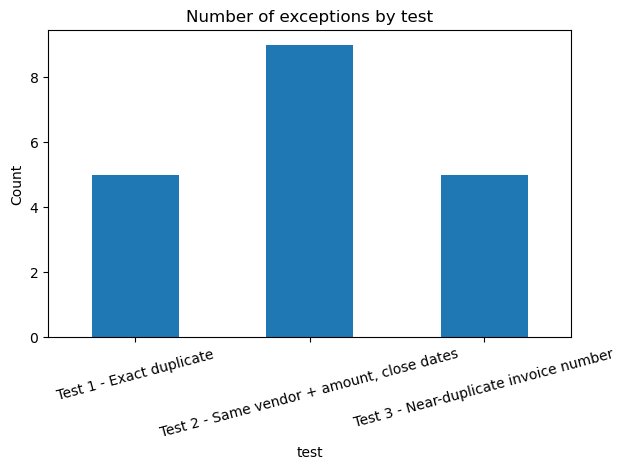

In [15]:
all_hits["test"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of exceptions by test")
plt.ylabel("Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("outputs/exceptions_by_test.png")
plt.show()

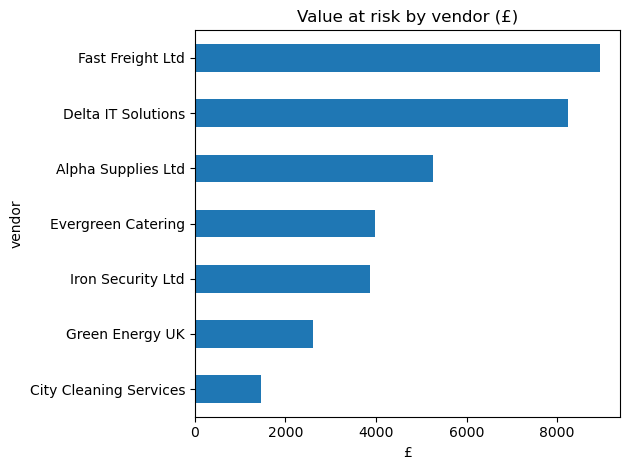

In [16]:
exceptions.groupby("vendor")["amount"].sum().sort_values().plot(kind="barh")
plt.title("Value at risk by vendor (£)")
plt.xlabel("£")
plt.tight_layout()
plt.savefig("outputs/value_at_risk_by_vendor.png")
plt.show()